In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler


In [2]:
data={
    "Annual Income" : [15,10,20,22,25,70,75,78,80,85],
    "Spending Score" : [80,85,78,90,82,20,25,15,22,18]
}


In [3]:
df=pd.DataFrame(data)
print(df)

   Annual Income  Spending Score
0             15              80
1             10              85
2             20              78
3             22              90
4             25              82
5             70              20
6             75              25
7             78              15
8             80              22
9             85              18


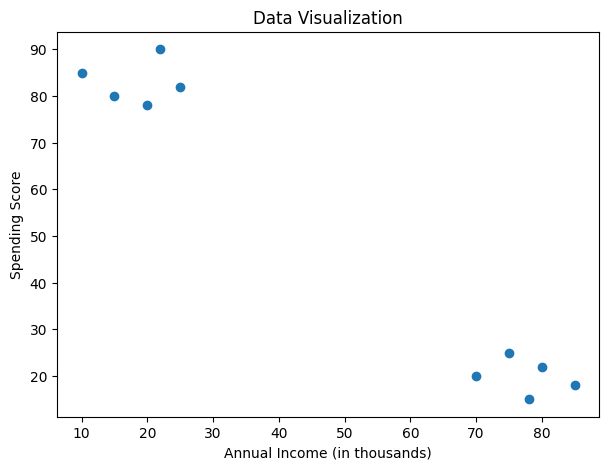

In [4]:
plt.figure(figsize=(7,5))
plt.scatter(
    df["Annual Income"],
    df["Spending Score"]
)
plt.xlabel("Annual Income (in thousands)")
plt.ylabel("Spending Score")
plt.title("Data Visualization")
plt.show()

In [5]:
X=df[["Annual Income","Spending Score"]]
scaler=StandardScaler()
X_scaled=scaler.fit_transform(X)
print(X_scaled.round(2))

[[-1.1   0.9 ]
 [-1.26  1.06]
 [-0.93  0.84]
 [-0.87  1.21]
 [-0.77  0.96]
 [ 0.73 -0.99]
 [ 0.9  -0.84]
 [ 1.   -1.15]
 [ 1.07 -0.93]
 [ 1.23 -1.06]]


In [6]:
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)

kmeans.fit(X_scaled)

df["Cluster"] = kmeans.labels_

print(df)

   Annual Income  Spending Score  Cluster
0             15              80        0
1             10              85        0
2             20              78        0
3             22              90        0
4             25              82        0
5             70              20        1
6             75              25        1
7             78              15        1
8             80              22        1
9             85              18        1


In [7]:
centroids_scaled=kmeans.cluster_centers_
centroids_original=scaler.inverse_transform(centroids_scaled)
print("cluster Centroids in original units : ")
print(centroids_original.round(2))

cluster Centroids in original units : 
[[18.4 83. ]
 [77.6 20. ]]


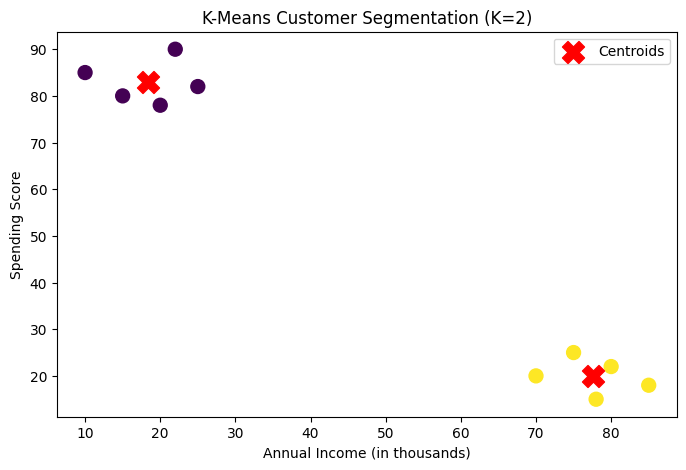

In [8]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["Annual Income"],
    df["Spending Score"],
    c=df["Cluster"],
    cmap="viridis",
    s=100
)

plt.scatter(
    centroids_original[:, 0],
    centroids_original[:, 1],
    color="red",
    marker="X",
    s=250,
    label="Centroids"
)

plt.xlabel("Annual Income (in thousands)")
plt.ylabel("Spending Score")
plt.title("K-Means Customer Segmentation (K=2)")
plt.legend()
plt.show()

In [9]:
data={
    "Annual Income" : [15,10,20,22,25,70,75,78,80,85],
    "Spending Score" : [80,85,78,90,82,20,25,15,22,18]
}

In [10]:
new_df=pd.DataFrame(data)
print(new_df)

   Annual Income  Spending Score
0             15              80
1             10              85
2             20              78
3             22              90
4             25              82
5             70              20
6             75              25
7             78              15
8             80              22
9             85              18


In [11]:
X = new_df[["Annual Income", "Spending Score"]]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

wcss = []

for k in range(1, 8):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

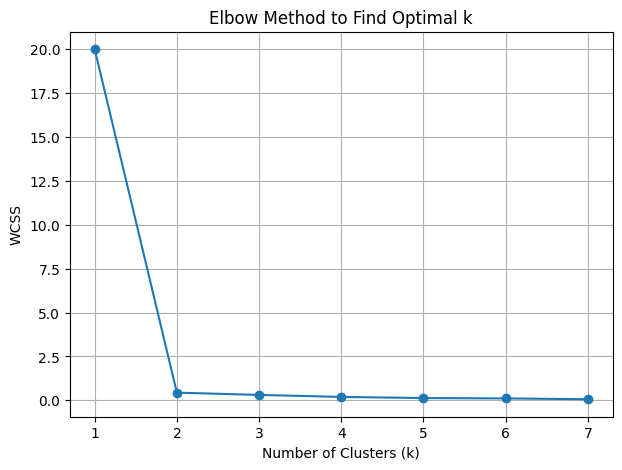

In [12]:
plt.figure(figsize=(7, 5))
plt.plot(range(1, 8), wcss, marker="o")

plt.xlabel("Number of Clusters (k)")
plt.ylabel("WCSS")
plt.title("Elbow Method to Find Optimal k")
plt.xticks(range(1, 8))
plt.grid(True)
plt.show()